# 🫁 Experiment 5: 4-Way Model Comparison
## CXR | CXR+Text | CXR+WBC | CXR+Text+WBC
### PneumoFusionNet | MIMIC-CXR PA (3,763 radiographs)

| Model | Inputs | Status |
|-------|--------|--------|
| **A** | CXR only | Load Phase 1 checkpoint |
| **B** | CXR + Report Text | Load Phase 2 checkpoint |
| **C** | CXR + WBC | **Train new** |
| **D** | CXR + Report Text + WBC | **Train new** |

All models share the **same canonical patient-level split** and are evaluated on the **same 562-radiograph test set**.
Threshold is selected on **validation data only** (Youden's J).


In [1]:
# --- CELL 0: Imports & Reproducibility ---
import os, random, warnings, json, copy, re, sys, time
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import seaborn as sns
import cv2
from PIL import Image
from tqdm.auto import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from transformers import AutoTokenizer, AutoModel
import torchxrayvision as xrv
from sklearn.metrics import (
    confusion_matrix, classification_report,
    roc_auc_score, roc_curve, accuracy_score, f1_score,
    average_precision_score, precision_recall_curve
)
from sklearn.preprocessing import StandardScaler

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'Device : {DEVICE}')
print(f'PyTorch: {torch.__version__}')

if r'C:\2026\PneumoFusionNet' not in sys.path:
    sys.path.insert(0, r'C:\2026\PneumoFusionNet')
from src.data.load_split import load_patient_split


Device : cuda
PyTorch: 2.5.1+cu121


In [2]:
# --- CELL 1: Configuration ---
DATASET_DIR  = r'C:\2026\PneumoFusionNet\mimic\main\dataset'
MAIN_DIR     = r'C:\2026\PneumoFusionNet\mimic\main'

PAIRED_CSV   = os.path.join(DATASET_DIR, 'phase3_paired_scaleup_final.csv')
P2_PAIRED    = os.path.join(DATASET_DIR, 'mimic_paired_dataset_phase2.csv')
SPLIT_CSV    = os.path.join(DATASET_DIR, 'patient_split.csv')
BBOX_CSV     = os.path.join(MAIN_DIR, 'outputs', 'Phase_1.1v4_PA_crossval_scaleup', 'lung_bboxes.csv')

P1_CKPT      = os.path.join(MAIN_DIR, 'outputs', 'Phase_1_NIH_single_split_exp2', 'phase1_best_model.pth')
P2_CKPT      = os.path.join(MAIN_DIR, 'outputs', 'Phase_2_NIH_single_split_exp2', 'best_phase2_model.pth')
P1_RES       = os.path.join(MAIN_DIR, 'outputs', 'Phase_1_NIH_single_split_exp2', 'phase1_results.json')
P2_RES       = os.path.join(MAIN_DIR, 'outputs', 'Phase_2_NIH_single_split_exp2', 'phase2_results.json')

SAVE_DIR     = os.path.join(MAIN_DIR, 'outputs', 'Experiment_5_4way_comparison')
os.makedirs(SAVE_DIR, exist_ok=True)

IMG_SIZE       = 224
MAX_TEXT_LEN   = 256
CLINBERT_MODEL = 'emilyalsentzer/Bio_ClinicalBERT'
IMG_FEAT_DIM   = 1024
TXT_FEAT_DIM   = 768
ATTN_DIM       = 512
ATTN_HEADS     = 8

BATCH_SIZE  = 16
EPOCHS      = 30
PATIENCE    = 8
FOCAL_GAMMA = 2.0
MIXUP_ALPHA = 0.2
CLASSES     = ['NORMAL', 'PNEUMONIA']
MEAN = [0.5020]; STD = [0.2703]
IMG_BASE = DATASET_DIR

for name, path in [('Paired CSV', PAIRED_CSV), ('Split CSV', SPLIT_CSV),
                    ('BBox CSV', BBOX_CSV), ('P1 ckpt', P1_CKPT), ('P2 ckpt', P2_CKPT)]:
    print(f'{name:12s}: {"OK" if os.path.exists(path) else "MISSING"} -> {path}')
print(f'Save dir    : {SAVE_DIR}')


Paired CSV  : OK -> C:\2026\PneumoFusionNet\mimic\main\dataset\phase3_paired_scaleup_final.csv
Split CSV   : OK -> C:\2026\PneumoFusionNet\mimic\main\dataset\patient_split.csv
BBox CSV    : OK -> C:\2026\PneumoFusionNet\mimic\main\outputs\Phase_1.1v4_PA_crossval_scaleup\lung_bboxes.csv
P1 ckpt     : OK -> C:\2026\PneumoFusionNet\mimic\main\outputs\Phase_1_NIH_single_split_exp2\phase1_best_model.pth
P2 ckpt     : OK -> C:\2026\PneumoFusionNet\mimic\main\outputs\Phase_2_NIH_single_split_exp2\best_phase2_model.pth
Save dir    : C:\2026\PneumoFusionNet\mimic\main\outputs\Experiment_5_4way_comparison


In [3]:
# --- CELL 2: Data Loading ---
def resolve_path(p):
    if pd.isna(p) or str(p).strip() == '': return ''
    p = str(p).replace('/', os.sep).replace('\\', os.sep)
    return p if os.path.isabs(p) else os.path.join(IMG_BASE, p)

df_raw = pd.read_csv(PAIRED_CSV)
df_raw['image_path']  = df_raw['image_path'].apply(resolve_path)
df_raw['report_path'] = df_raw['report_path'].apply(resolve_path)

if os.path.exists(P2_PAIRED):
    p2_meta = pd.read_csv(P2_PAIRED)[['dicom_id', 'indication', 'findings']]
    df_raw = df_raw.merge(p2_meta, on='dicom_id', how='left')
    print(f'Merged indication & findings from Phase 2: {len(df_raw)} rows')

print(f'Loaded {len(df_raw):,} rows | Labels: {df_raw["label"].value_counts().to_dict()}')


Merged indication & findings from Phase 2: 3763 rows
Loaded 3,763 rows | Labels: {1: 1891, 0: 1872}


In [4]:
# --- CELL 3: Text Preparation (FINDINGS + INDICATION only, no raw-report fallback) ---
LEAKAGE_RE = re.compile(
    r'\bpneumonia\b|\bpneumonic\b|\bno[ -]acute[ -]\w+|\bno finding\w*'
    r'|\bcompatible with\b|\bconsistent with\b|\bnormal study\b|\bno significant\b',
    re.IGNORECASE
)

def build_report_text(row):
    parts = []
    ind = str(row.get('indication', '')).strip()
    if ind and ind.lower() != 'nan' and len(ind) > 3:
        parts.append(ind)
    find = str(row.get('findings', '')).strip()
    if find and find.lower() != 'nan' and len(find) > 3:
        parts.append(find)
    result = ' '.join(parts).strip()
    result = LEAKAGE_RE.sub('[REDACTED]', result)
    return result

text_df = df_raw.copy()
text_df['report_rich'] = text_df.apply(build_report_text, axis=1)

n_total = len(text_df)
n_empty = (text_df['report_rich'].str.strip() == '').sum()
print(f'Reports with valid FINDINGS/INDICATION: {n_total - n_empty}/{n_total} ({100*(n_total-n_empty)/n_total:.1f}%)')
print(f'Empty reports after section extraction: {n_empty} ({100*n_empty/n_total:.1f}%)')
print(f'Raw-report fallback: REMOVED')


Reports with valid FINDINGS/INDICATION: 3545/3763 (94.2%)
Empty reports after section extraction: 218 (5.8%)
Raw-report fallback: REMOVED


In [5]:
# --- CELL 4: WBC Availability, Split, Imputation, Scaling ---
df = text_df.copy()
df = df[df['label'].notna()].reset_index(drop=True)
df['label'] = df['label'].astype(int)

train_df, val_df, test_df = load_patient_split(df, SPLIT_CSV)

print('=' * 70)
print('CANONICAL PATIENT-LEVEL SPLIT')
print('=' * 70)
for name, split in [('Train', train_df), ('Val', val_df), ('Test', test_df)]:
    n0 = (split['label']==0).sum(); n1 = (split['label']==1).sum()
    wbc_ok = split['wbc'].notna().sum()
    print(f'  {name:5s}: {len(split):5d} CXRs | {split["subject_id"].nunique():4d} patients '
          f'| Normal={n0}, Pneumonia={n1} | WBC avail: {wbc_ok}/{len(split)} ({100*wbc_ok/len(split):.1f}%)')
print('=' * 70)

n_wbc_avail = df['wbc'].notna().sum()
n_wbc_miss  = df['wbc'].isna().sum()
print(f'\nWBC Biomarker Summary:')
print(f'  Available: {n_wbc_avail}/{len(df)} ({100*n_wbc_avail/len(df):.1f}%)')
print(f'  Missing:   {n_wbc_miss}/{len(df)} ({100*n_wbc_miss/len(df):.1f}%)')
print(f'  Imputation: Train-set median')

wbc_train_median = train_df['wbc'].median()
print(f'  Train WBC median: {wbc_train_median:.2f}')
for sdf in [train_df, val_df, test_df]:
    sdf['wbc'] = sdf['wbc'].fillna(wbc_train_median).astype(float)

wbc_scaler = StandardScaler()
train_df[['wbc']] = wbc_scaler.fit_transform(train_df[['wbc']].values)
val_df[['wbc']]   = wbc_scaler.transform(val_df[['wbc']].values)
test_df[['wbc']]  = wbc_scaler.transform(test_df[['wbc']].values)
print(f'  WBC scaled (fit on train only)')


CANONICAL PATIENT-LEVEL SPLIT
  Train:  2635 CXRs | 2382 patients | Normal=1311, Pneumonia=1324 | WBC avail: 2125/2635 (80.6%)
  Val  :   566 CXRs |  511 patients | Normal=278, Pneumonia=288 | WBC avail: 453/566 (80.0%)
  Test :   562 CXRs |  511 patients | Normal=283, Pneumonia=279 | WBC avail: 451/562 (80.2%)

WBC Biomarker Summary:
  Available: 3029/3763 (80.5%)
  Missing:   734/3763 (19.5%)
  Imputation: Train-set median
  Train WBC median: 7.30
  WBC scaled (fit on train only)


In [6]:
# --- CELL 5: Bbox Lookup & Dataset Classes ---
bbox_df     = pd.read_csv(BBOX_CSV)
bbox_lookup = bbox_df.set_index('image_path').to_dict('index')
print(f'Bbox entries: {len(bbox_lookup)}')

val_tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
train_tfm = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(8),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])

clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8,8))

def load_image(img_path, transform):
    img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    if img is None: img = np.zeros((224,224), dtype=np.uint8)
    img = clahe.apply(img)
    bb = bbox_lookup.get(img_path, None)
    if bb and bb.get('x_max',0) > 0:
        img = img[bb['y_min']:bb['y_max'], bb['x_min']:bb['x_max']]
    return transform(Image.fromarray(img))

class CXROnlyDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True); self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        return load_image(row.image_path, self.transform), int(row.label)

class CXRWBCDataset(Dataset):
    def __init__(self, df, transform):
        self.df = df.reset_index(drop=True); self.transform = transform
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = load_image(row.image_path, self.transform)
        wbc = torch.tensor([float(row.wbc)], dtype=torch.float32)
        return img, wbc, int(row.label)

class CXRTextDataset(Dataset):
    def __init__(self, df, tokenizer, transform, max_len=MAX_TEXT_LEN):
        self.df = df.reset_index(drop=True); self.tokenizer = tokenizer
        self.transform = transform; self.max_len = max_len
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = load_image(row.image_path, self.transform)
        enc = self.tokenizer(row.report_rich, max_length=self.max_len,
                             padding='max_length', truncation=True, return_tensors='pt')
        return img, enc['input_ids'].squeeze(0), enc['attention_mask'].squeeze(0), int(row.label)

class CXRTextWBCDataset(Dataset):
    def __init__(self, df, tokenizer, transform, max_len=MAX_TEXT_LEN):
        self.df = df.reset_index(drop=True); self.tokenizer = tokenizer
        self.transform = transform; self.max_len = max_len
    def __len__(self): return len(self.df)
    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = load_image(row.image_path, self.transform)
        enc = self.tokenizer(row.report_rich, max_length=self.max_len,
                             padding='max_length', truncation=True, return_tensors='pt')
        wbc = torch.tensor([float(row.wbc)], dtype=torch.float32)
        return img, enc['input_ids'].squeeze(0), enc['attention_mask'].squeeze(0), wbc, int(row.label)

print('All dataset classes defined.')


Bbox entries: 3744
All dataset classes defined.


In [7]:
# --- CELL 6: Model Architectures ---

class ChannelAttention(nn.Module):
    def __init__(self, channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.mlp = nn.Sequential(
            nn.Conv2d(channels, channels // reduction, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(channels // reduction, channels, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        return x * self.sigmoid(self.mlp(self.avg_pool(x)) + self.mlp(self.max_pool(x)))

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        avg_out = x.mean(dim=1, keepdim=True)
        max_out = x.max(dim=1, keepdim=True)[0]
        return x * self.sigmoid(self.conv(torch.cat([avg_out, max_out], dim=1)))

class CBAM(nn.Module):
    def __init__(self, channels=1024, reduction=16, r=None):
        super().__init__()
        if r is not None: reduction = r
        self.channel_att = ChannelAttention(channels, reduction)
        self.spatial_att = SpatialAttention()
    def forward(self, x):
        return self.spatial_att(self.channel_att(x))

class ImageEncoder(nn.Module):
    def __init__(self, ckpt):
        super().__init__()
        xrv_m = xrv.models.DenseNet(weights=None)
        self.features = xrv_m.features; self.cbam = CBAM(1024, reduction=16); self.pool = nn.AdaptiveAvgPool2d(1)
        sd = {k:v for k,v in torch.load(ckpt, map_location='cpu').items()
              if k.startswith('features.') or k.startswith('cbam.')}
        miss, unexp = self.load_state_dict(sd, strict=False)
        print(f'[ImageEncoder] loaded {len(sd)} keys | missing={len(miss)} unexpected={len(unexp)}')
        for p in self.parameters(): p.requires_grad = False
    def forward(self, x):
        f = F.relu(self.features(x), inplace=True); f = self.cbam(f)
        return self.pool(f).flatten(1)

class TextEncoder(nn.Module):
    def __init__(self, model_name=CLINBERT_MODEL):
        super().__init__()
        try: self.bert = AutoModel.from_pretrained(model_name, local_files_only=True)
        except: self.bert = AutoModel.from_pretrained(model_name)
        for name, p in self.bert.named_parameters():
            if 'encoder.layer.10' in name or 'encoder.layer.11' in name or 'pooler' in name:
                p.requires_grad = True
            else: p.requires_grad = False
        trainable = sum(p.numel() for p in self.bert.parameters() if p.requires_grad)
        print(f'[TextEncoder] Unfrozen BERT params: {trainable:,}')
    def forward(self, input_ids, attention_mask):
        return self.bert(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state

class ImageOnlyClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        xrv_m = xrv.models.DenseNet(weights=None)
        self.features = xrv_m.features; self.cbam = CBAM(1024, reduction=16); self.pool = nn.AdaptiveAvgPool2d(1)
        self.classifier = nn.Sequential(
            nn.Dropout(0.5), nn.Linear(1024, 512), nn.BatchNorm1d(512), nn.ReLU(inplace=True),
            nn.Dropout(0.3), nn.Linear(512, 128), nn.BatchNorm1d(128), nn.ReLU(inplace=True),
            nn.Dropout(0.2), nn.Linear(128, 2)
        )
    def forward(self, x):
        f = F.relu(self.features(x), inplace=True); f = self.cbam(f); f = self.pool(f).flatten(1)
        return self.classifier(f)

class CrossAttnFusionNet(nn.Module):
    def __init__(self, img_dim=IMG_FEAT_DIM, txt_dim=TXT_FEAT_DIM, attn_dim=ATTN_DIM, heads=ATTN_HEADS):
        super().__init__()
        self.query_proj = nn.Linear(img_dim, attn_dim)
        self.key_proj   = nn.Linear(txt_dim, attn_dim)
        self.val_proj   = nn.Linear(txt_dim, attn_dim)
        self.cross_attn = nn.MultiheadAttention(attn_dim, heads, batch_first=True, dropout=0.1)
        self.norm1      = nn.LayerNorm(attn_dim)
        fused_dim = img_dim + attn_dim
        self.classifier = nn.Sequential(
            nn.LayerNorm(fused_dim), nn.Dropout(0.4),
            nn.Linear(fused_dim, 512), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(512, 128), nn.GELU(), nn.Dropout(0.2), nn.Linear(128, 2))
    def forward(self, img_feat, txt_tokens, text_mask=None):
        q = self.query_proj(img_feat).unsqueeze(1)
        k = self.key_proj(txt_tokens); v = self.val_proj(txt_tokens)
        kpm = (text_mask == 0) if text_mask is not None else None
        attended, _ = self.cross_attn(q, k, v, key_padding_mask=kpm)
        attended = self.norm1(attended.squeeze(1))
        return self.classifier(torch.cat([img_feat, attended], dim=1))

class ImageWBCFusionNet(nn.Module):
    def __init__(self, img_dim=IMG_FEAT_DIM):
        super().__init__()
        self.wbc_embed = nn.Sequential(nn.Linear(1, 32), nn.ReLU(), nn.Dropout(0.2),
                                       nn.Linear(32, 32), nn.ReLU())
        fused_dim = img_dim + 32
        self.classifier = nn.Sequential(
            nn.LayerNorm(fused_dim), nn.Dropout(0.4),
            nn.Linear(fused_dim, 256), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(256, 64), nn.GELU(), nn.Dropout(0.2), nn.Linear(64, 2))
        print(f'[ImageWBCFusionNet] fused_dim={fused_dim} | params={sum(p.numel() for p in self.parameters()):,}')
    def forward(self, img_feat, wbc):
        return self.classifier(torch.cat([img_feat, self.wbc_embed(wbc)], dim=1))

class ImageTextWBCFusionNet(nn.Module):
    def __init__(self, img_dim=IMG_FEAT_DIM, txt_dim=TXT_FEAT_DIM, attn_dim=ATTN_DIM, heads=ATTN_HEADS):
        super().__init__()
        self.query_proj = nn.Linear(img_dim, attn_dim)
        self.key_proj   = nn.Linear(txt_dim, attn_dim)
        self.val_proj   = nn.Linear(txt_dim, attn_dim)
        self.cross_attn = nn.MultiheadAttention(attn_dim, heads, batch_first=True, dropout=0.1)
        self.norm1      = nn.LayerNorm(attn_dim)
        self.wbc_embed = nn.Sequential(nn.Linear(1, 32), nn.ReLU(), nn.Dropout(0.2),
                                       nn.Linear(32, 32), nn.ReLU())
        fused_dim = img_dim + attn_dim + 32
        self.classifier = nn.Sequential(
            nn.LayerNorm(fused_dim), nn.Dropout(0.4),
            nn.Linear(fused_dim, 512), nn.GELU(), nn.Dropout(0.3),
            nn.Linear(512, 128), nn.GELU(), nn.Dropout(0.2), nn.Linear(128, 2))
        print(f'[ImageTextWBCFusionNet] fused_dim={fused_dim} | params={sum(p.numel() for p in self.parameters()):,}')
    def forward(self, img_feat, txt_tokens, wbc, text_mask=None):
        q = self.query_proj(img_feat).unsqueeze(1)
        k = self.key_proj(txt_tokens); v = self.val_proj(txt_tokens)
        kpm = (text_mask == 0) if text_mask is not None else None
        attended, _ = self.cross_attn(q, k, v, key_padding_mask=kpm)
        attended = self.norm1(attended.squeeze(1))
        wbc_f = self.wbc_embed(wbc)
        return self.classifier(torch.cat([img_feat, attended, wbc_f], dim=1))

print('All model architectures defined.')


All model architectures defined.

In [8]:
# --- CELL 7: Focal Loss, Mixup, Eval Helpers ---
class FocalLoss(nn.Module):
    def __init__(self, gamma=FOCAL_GAMMA, weight=None):
        super().__init__()
        self.gamma = gamma; self.weight = weight
    def forward(self, logits, targets):
        ce = F.cross_entropy(logits, targets, weight=self.weight, reduction='none')
        pt = torch.exp(-ce)
        return ((1 - pt) ** self.gamma * ce).mean()

def mixup_criterion(criterion, logits, y_a, y_b, lam):
    return lam * criterion(logits, y_a) + (1 - lam) * criterion(logits, y_b)

def compute_metrics(labels, probs, threshold):
    preds = (np.array(probs) >= threshold).astype(int)
    labels = np.array(labels)
    cm = confusion_matrix(labels, preds)
    tn, fp, fn, tp = cm.ravel()
    sens = tp / (tp + fn) if (tp + fn) > 0 else 0
    spec = tn / (tn + fp) if (tn + fp) > 0 else 0
    acc  = (tp + tn) / (tp + tn + fp + fn)
    f1v  = f1_score(labels, preds)
    auc  = roc_auc_score(labels, probs)
    pr_auc = average_precision_score(labels, probs)
    return {'roc_auc': round(auc, 4), 'pr_auc': round(pr_auc, 4),
            'accuracy': round(acc, 4), 'sensitivity': round(sens, 4),
            'specificity': round(spec, 4), 'f1': round(f1v, 4),
            'threshold': round(threshold, 4),
            'confusion_matrix': {'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}}

def select_threshold(labels, probs):
    fpr, tpr, thresholds = roc_curve(labels, probs)
    return float(thresholds[np.argmax(tpr - fpr)])

print('Loss, mixup & eval helpers ready.')


Loss, mixup & eval helpers ready.


In [9]:
# --- CELL 8: Model A — CXR Only (Load Phase 1 & Evaluate) ---
print('=' * 70)
print('MODEL A: CXR ONLY')
print('=' * 70)

model_a = ImageOnlyClassifier().to(DEVICE)
p1_state = torch.load(P1_CKPT, map_location=DEVICE)
model_a.load_state_dict(p1_state, strict=True)
model_a.eval()
print(f'Loaded Phase 1 checkpoint')

val_ds_a  = CXROnlyDataset(val_df, val_tfm)
test_ds_a = CXROnlyDataset(test_df, val_tfm)
val_loader_a  = DataLoader(val_ds_a,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader_a = DataLoader(test_ds_a, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

val_probs_a, val_labels_a = [], []
with torch.no_grad():
    for imgs, labels in tqdm(val_loader_a, desc='Model A Val'):
        imgs = imgs.to(DEVICE)
        probs = F.softmax(model_a(imgs), dim=1)[:,1].cpu().numpy()
        val_probs_a.extend(probs); val_labels_a.extend(labels.numpy())

thresh_a = select_threshold(val_labels_a, val_probs_a)
print(f'Val threshold (Youden J): {thresh_a:.4f}')

test_probs_a, test_labels_a = [], []
with torch.no_grad():
    for imgs, labels in tqdm(test_loader_a, desc='Model A Test'):
        imgs = imgs.to(DEVICE)
        probs = F.softmax(model_a(imgs), dim=1)[:,1].cpu().numpy()
        test_probs_a.extend(probs); test_labels_a.extend(labels.numpy())

results_a = compute_metrics(test_labels_a, test_probs_a, thresh_a)
results_a['model'] = 'A: CXR Only'
print(f'Model A: AUC={results_a["roc_auc"]}, Acc={results_a["accuracy"]}, '
      f'Sens={results_a["sensitivity"]}, Spec={results_a["specificity"]}, F1={results_a["f1"]}')
del model_a; torch.cuda.empty_cache()


MODEL A: CXR ONLY


Loaded Phase 1 checkpoint


Model A Val:   0%|          | 0/36 [00:00<?, ?it/s]

Val threshold (Youden J): 0.5392


Model A Test:   0%|          | 0/36 [00:00<?, ?it/s]

Model A: AUC=0.8072, Acc=0.7349, Sens=0.7742, Spec=0.6961, F1=0.7435


In [10]:
# --- CELL 9: Model B — CXR + Text (Load Phase 2 & Evaluate) ---
print('=' * 70)
print('MODEL B: CXR + REPORT TEXT')
print('=' * 70)

print('Loading ClinicalBERT tokenizer...')
try: tokenizer = AutoTokenizer.from_pretrained(CLINBERT_MODEL, local_files_only=True)
except: tokenizer = AutoTokenizer.from_pretrained(CLINBERT_MODEL)

image_encoder_b = ImageEncoder(P1_CKPT).to(DEVICE)
text_encoder_b  = TextEncoder(CLINBERT_MODEL).to(DEVICE)
fusion_b        = CrossAttnFusionNet().to(DEVICE)

p2_state = torch.load(P2_CKPT, map_location=DEVICE)
if isinstance(p2_state, dict) and 'fusion' in p2_state:
    fusion_b.load_state_dict(p2_state['fusion'])
    text_encoder_b.load_state_dict(p2_state['text'])
    print('Loaded Phase 2 checkpoint (fusion + text)')
else:
    fusion_b.load_state_dict(p2_state)
    print('Loaded Phase 2 checkpoint (direct)')

image_encoder_b.eval(); text_encoder_b.eval(); fusion_b.eval()

val_ds_b  = CXRTextDataset(val_df, tokenizer, val_tfm)
test_ds_b = CXRTextDataset(test_df, tokenizer, val_tfm)
val_loader_b  = DataLoader(val_ds_b,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader_b = DataLoader(test_ds_b, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

val_probs_b, val_labels_b = [], []
with torch.no_grad():
    for imgs, ids, masks, labels in tqdm(val_loader_b, desc='Model B Val'):
        imgs, ids, masks = imgs.to(DEVICE), ids.to(DEVICE), masks.to(DEVICE)
        img_f = image_encoder_b(imgs); txt_t = text_encoder_b(ids, masks)
        probs = F.softmax(fusion_b(img_f, txt_t, text_mask=masks), dim=1)[:,1].cpu().numpy()
        val_probs_b.extend(probs); val_labels_b.extend(labels.numpy())

thresh_b = select_threshold(val_labels_b, val_probs_b)
print(f'Val threshold (Youden J): {thresh_b:.4f}')

test_probs_b, test_labels_b = [], []
with torch.no_grad():
    for imgs, ids, masks, labels in tqdm(test_loader_b, desc='Model B Test'):
        imgs, ids, masks = imgs.to(DEVICE), ids.to(DEVICE), masks.to(DEVICE)
        img_f = image_encoder_b(imgs); txt_t = text_encoder_b(ids, masks)
        probs = F.softmax(fusion_b(img_f, txt_t, text_mask=masks), dim=1)[:,1].cpu().numpy()
        test_probs_b.extend(probs); test_labels_b.extend(labels.numpy())

results_b = compute_metrics(test_labels_b, test_probs_b, thresh_b)
results_b['model'] = 'B: CXR + Text'
print(f'Model B: AUC={results_b["roc_auc"]}, Acc={results_b["accuracy"]}, '
      f'Sens={results_b["sensitivity"]}, Spec={results_b["specificity"]}, F1={results_b["f1"]}')
del text_encoder_b, fusion_b; torch.cuda.empty_cache()


MODEL B: CXR + REPORT TEXT
Loading ClinicalBERT tokenizer...


[ImageEncoder] loaded 728 keys | missing=0 unexpected=0


[TextEncoder] Unfrozen BERT params: 14,766,336


Loaded Phase 2 checkpoint (fusion + text)


Model B Val:   0%|          | 0/36 [00:00<?, ?it/s]

Val threshold (Youden J): 0.5757


Model B Test:   0%|          | 0/36 [00:00<?, ?it/s]

Model B: AUC=0.9475, Acc=0.8808, Sens=0.871, Spec=0.8905, F1=0.8788


In [11]:
# --- CELL 10: Model C — CXR + WBC (Train New) ---
print('=' * 70)
print('MODEL C: CXR + WBC (Training new model)')
print('=' * 70)

MODEL_C_PATH = os.path.join(SAVE_DIR, 'best_model_C_cxr_wbc.pth')

image_encoder_c = ImageEncoder(P1_CKPT).to(DEVICE)
fusion_c = ImageWBCFusionNet().to(DEVICE)

if os.path.exists(MODEL_C_PATH):
    print(f'[FAST RESUME] Loading existing Model C checkpoint')
    state_c = torch.load(MODEL_C_PATH, map_location=DEVICE)
    fusion_c.load_state_dict(state_c['fusion'])
    best_auc_c = state_c.get('best_val_auc', 0.0)
    history_c = state_c.get('history', {'train_loss':[], 'val_loss':[], 'train_auc':[], 'val_auc':[]})
    print(f'  Best val AUC: {best_auc_c:.4f}')
else:
    print('Training from scratch...')
    train_ds_c = CXRWBCDataset(train_df, train_tfm)
    val_ds_c   = CXRWBCDataset(val_df, val_tfm)
    train_loader_c = DataLoader(train_ds_c, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True)
    val_loader_c   = DataLoader(val_ds_c,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    n0 = (train_df['label']==0).sum(); n1 = (train_df['label']==1).sum()
    w = torch.tensor([1.0, n0/n1], dtype=torch.float32).to(DEVICE)
    criterion_c = FocalLoss(gamma=FOCAL_GAMMA, weight=w)
    optimizer_c = torch.optim.AdamW(fusion_c.parameters(), lr=2e-4, weight_decay=1e-4)
    scheduler_c = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_c, T_max=EPOCHS)

    best_auc_c = 0.0; patience_cnt_c = 0; best_state_c = None
    history_c = {'train_loss':[], 'val_loss':[], 'train_auc':[], 'val_auc':[]}

    for epoch in range(1, EPOCHS+1):
        fusion_c.train()
        ep_loss, ep_probs, ep_labels = 0.0, [], []
        for imgs, wbcs, labels in train_loader_c:
            imgs, wbcs, labels = imgs.to(DEVICE), wbcs.to(DEVICE), labels.to(DEVICE)
            with torch.no_grad(): img_f = image_encoder_c(imgs)
            lam = np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA) if MIXUP_ALPHA > 0 else 1.0
            idx = torch.randperm(img_f.size(0), device=DEVICE)
            img_m = img_f*lam + img_f[idx]*(1-lam)
            wbc_m = wbcs*lam + wbcs[idx]*(1-lam)
            la, lb = labels, labels[idx]
            optimizer_c.zero_grad()
            logits = fusion_c(img_m, wbc_m)
            loss = mixup_criterion(criterion_c, logits, la, lb, lam)
            loss.backward()
            nn.utils.clip_grad_norm_(fusion_c.parameters(), 1.0)
            optimizer_c.step()
            probs = F.softmax(logits.detach(), dim=1)[:,1].cpu().numpy()
            ep_loss += loss.item()*labels.size(0)
            ep_probs.extend(probs); ep_labels.extend(labels.cpu().tolist())

        scheduler_c.step()
        tr_loss = ep_loss/len(ep_labels)
        tr_auc = roc_auc_score(ep_labels, ep_probs) if len(set(ep_labels))>1 else 0.5

        fusion_c.eval()
        v_loss, v_probs, v_labels = 0.0, [], []
        with torch.no_grad():
            for imgs, wbcs, labels in val_loader_c:
                imgs, wbcs, labels = imgs.to(DEVICE), wbcs.to(DEVICE), labels.to(DEVICE)
                img_f = image_encoder_c(imgs)
                logits = fusion_c(img_f, wbcs)
                loss = criterion_c(logits, labels)
                probs = F.softmax(logits, dim=1)[:,1].cpu().numpy()
                v_loss += loss.item()*labels.size(0)
                v_probs.extend(probs); v_labels.extend(labels.cpu().tolist())
        val_loss = v_loss/len(v_labels)
        val_auc = roc_auc_score(v_labels, v_probs) if len(set(v_labels))>1 else 0.5
        history_c['train_loss'].append(tr_loss); history_c['val_loss'].append(val_loss)
        history_c['train_auc'].append(tr_auc); history_c['val_auc'].append(val_auc)
        marker = ''
        if val_auc > best_auc_c:
            best_auc_c = val_auc
            best_state_c = copy.deepcopy({'fusion': fusion_c.state_dict(),
                                          'best_val_auc': best_auc_c, 'history': history_c})
            torch.save(best_state_c, MODEL_C_PATH)
            patience_cnt_c = 0; marker = ' <-- best'
        else: patience_cnt_c += 1
        print(f'Ep {epoch:03d}/{EPOCHS} | tr_loss={tr_loss:.4f} tr_auc={tr_auc:.4f} '
              f'| val_loss={val_loss:.4f} val_auc={val_auc:.4f}{marker}', flush=True)
        if patience_cnt_c >= PATIENCE:
            print(f'Early stop at epoch {epoch}.'); break

    best_ckpt = torch.load(MODEL_C_PATH, map_location=DEVICE)
    fusion_c.load_state_dict(best_ckpt['fusion'])
    print(f'Best Val AUC (Model C): {best_auc_c:.4f}')
print('Model C ready.')


MODEL C: CXR + WBC (Training new model)


[ImageEncoder] loaded 728 keys | missing=0 unexpected=0
[ImageWBCFusionNet] fused_dim=1056 | params=290,402
Training from scratch...


Ep 001/30 | tr_loss=0.1578 tr_auc=0.6248 | val_loss=0.1438 val_auc=0.7649 <-- best


Ep 002/30 | tr_loss=0.1531 tr_auc=0.6189 | val_loss=0.1449 val_auc=0.7607


Ep 003/30 | tr_loss=0.1518 tr_auc=0.6136 | val_loss=0.1443 val_auc=0.7633


Ep 004/30 | tr_loss=0.1520 tr_auc=0.6347 | val_loss=0.1474 val_auc=0.7616


... (2 outputs left out)

Ep 007/30 | tr_loss=0.1501 tr_auc=0.6320 | val_loss=0.1455 val_auc=0.7569


Ep 008/30 | tr_loss=0.1517 tr_auc=0.6263 | val_loss=0.1442 val_auc=0.7623


Ep 009/30 | tr_loss=0.1497 tr_auc=0.6452 | val_loss=0.1456 val_auc=0.7577


Early stop at epoch 9.
Best Val AUC (Model C): 0.7649
Model C ready.


In [12]:
# --- CELL 11: Model C — Evaluation ---
fusion_c.eval(); image_encoder_c.eval()

val_ds_c2  = CXRWBCDataset(val_df, val_tfm)
test_ds_c2 = CXRWBCDataset(test_df, val_tfm)
val_loader_c2  = DataLoader(val_ds_c2,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader_c2 = DataLoader(test_ds_c2, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

val_probs_c, val_labels_c = [], []
with torch.no_grad():
    for imgs, wbcs, labels in tqdm(val_loader_c2, desc='Model C Val'):
        imgs, wbcs = imgs.to(DEVICE), wbcs.to(DEVICE)
        img_f = image_encoder_c(imgs)
        probs = F.softmax(fusion_c(img_f, wbcs), dim=1)[:,1].cpu().numpy()
        val_probs_c.extend(probs); val_labels_c.extend(labels.numpy())

thresh_c = select_threshold(val_labels_c, val_probs_c)
print(f'Val threshold (Youden J): {thresh_c:.4f}')

test_probs_c, test_labels_c = [], []
with torch.no_grad():
    for imgs, wbcs, labels in tqdm(test_loader_c2, desc='Model C Test'):
        imgs, wbcs = imgs.to(DEVICE), wbcs.to(DEVICE)
        img_f = image_encoder_c(imgs)
        probs = F.softmax(fusion_c(img_f, wbcs), dim=1)[:,1].cpu().numpy()
        test_probs_c.extend(probs); test_labels_c.extend(labels.numpy())

results_c = compute_metrics(test_labels_c, test_probs_c, thresh_c)
results_c['model'] = 'C: CXR + WBC'
print(f'Model C: AUC={results_c["roc_auc"]}, Acc={results_c["accuracy"]}, '
      f'Sens={results_c["sensitivity"]}, Spec={results_c["specificity"]}, F1={results_c["f1"]}')
del image_encoder_c, fusion_c; torch.cuda.empty_cache()


Model C Val:   0%|          | 0/36 [00:00<?, ?it/s]

Val threshold (Youden J): 0.5412


Model C Test:   0%|          | 0/36 [00:00<?, ?it/s]

Model C: AUC=0.8139, Acc=0.7224, Sens=0.5627, Spec=0.8799, F1=0.6681


In [13]:
# --- CELL 12: Model D — CXR + Text + WBC (Train New) ---
print('=' * 70)
print('MODEL D: CXR + TEXT + WBC (Training new model)')
print('=' * 70)

MODEL_D_PATH = os.path.join(SAVE_DIR, 'best_model_D_cxr_text_wbc.pth')

image_encoder_d = ImageEncoder(P1_CKPT).to(DEVICE)
text_encoder_d  = TextEncoder(CLINBERT_MODEL).to(DEVICE)
fusion_d        = ImageTextWBCFusionNet().to(DEVICE)

# Pre-load fine-tuned ClinicalBERT & cross-attention weights from Phase 2
if os.path.exists(P2_CKPT):
    p2_init = torch.load(P2_CKPT, map_location='cpu')
    if 'text' in p2_init:
        text_encoder_d.load_state_dict(p2_init['text'], strict=False)
        print('  [Model D] Pre-loaded fine-tuned ClinicalBERT weights from Phase 2')
    if 'fusion' in p2_init:
        ca_keys = {k:v for k,v in p2_init['fusion'].items()
                   if any(k.startswith(pfx) for pfx in ['query_proj','key_proj','val_proj','cross_attn','norm1'])}
        fusion_d.load_state_dict(ca_keys, strict=False)
        print(f'  [Model D] Pre-loaded {len(ca_keys)} cross-attention keys from Phase 2')

if os.path.exists(MODEL_D_PATH):
    print(f'[FAST RESUME] Loading existing Model D checkpoint')
    state_d = torch.load(MODEL_D_PATH, map_location=DEVICE)
    fusion_d.load_state_dict(state_d['fusion'])
    text_encoder_d.load_state_dict(state_d['text'])
    best_auc_d = state_d.get('best_val_auc', 0.0)
    history_d = state_d.get('history', {'train_loss':[], 'val_loss':[], 'train_auc':[], 'val_auc':[]})
    print(f'  Best val AUC: {best_auc_d:.4f}')
else:
    print('Training from scratch...')
    train_ds_d = CXRTextWBCDataset(train_df, tokenizer, train_tfm)
    val_ds_d   = CXRTextWBCDataset(val_df, tokenizer, val_tfm)
    train_loader_d = DataLoader(train_ds_d, batch_size=BATCH_SIZE, shuffle=True, num_workers=0, drop_last=True)
    val_loader_d   = DataLoader(val_ds_d,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

    n0 = (train_df['label']==0).sum(); n1 = (train_df['label']==1).sum()
    w = torch.tensor([1.0, n0/n1], dtype=torch.float32).to(DEVICE)
    criterion_d = FocalLoss(gamma=FOCAL_GAMMA, weight=w)
    optimizer_d = torch.optim.AdamW([
        {'params': fusion_d.parameters(), 'lr': 2e-4},
        {'params': [p for p in text_encoder_d.parameters() if p.requires_grad], 'lr': 1e-5},
    ], weight_decay=1e-4)
    scheduler_d = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer_d, T_max=EPOCHS)

    best_auc_d = 0.0; patience_cnt_d = 0; best_state_d = None
    history_d = {'train_loss':[], 'val_loss':[], 'train_auc':[], 'val_auc':[]}

    for epoch in range(1, EPOCHS+1):
        fusion_d.train(); text_encoder_d.train()
        ep_loss, ep_probs, ep_labels = 0.0, [], []
        for imgs, ids, masks, wbcs, labels in train_loader_d:
            imgs = imgs.to(DEVICE); ids = ids.to(DEVICE); masks = masks.to(DEVICE)
            wbcs = wbcs.to(DEVICE); labels = labels.to(DEVICE)
            with torch.no_grad(): img_f = image_encoder_d(imgs)
            txt_t = text_encoder_d(ids, masks)
            lam = np.random.beta(MIXUP_ALPHA, MIXUP_ALPHA) if MIXUP_ALPHA > 0 else 1.0
            idx = torch.randperm(img_f.size(0), device=DEVICE)
            img_m = img_f*lam + img_f[idx]*(1-lam)
            txt_m = txt_t*lam + txt_t[idx]*(1-lam)
            wbc_m = wbcs*lam + wbcs[idx]*(1-lam)
            la, lb = labels, labels[idx]
            optimizer_d.zero_grad()
            logits = fusion_d(img_m, txt_m, wbc_m, text_mask=masks)
            loss = mixup_criterion(criterion_d, logits, la, lb, lam)
            loss.backward()
            all_params = list(fusion_d.parameters()) + list(text_encoder_d.parameters())
            nn.utils.clip_grad_norm_(all_params, 1.0)
            optimizer_d.step()
            probs = F.softmax(logits.detach(), dim=1)[:,1].cpu().numpy()
            ep_loss += loss.item()*labels.size(0)
            ep_probs.extend(probs); ep_labels.extend(labels.cpu().tolist())

        scheduler_d.step()
        tr_loss = ep_loss/len(ep_labels)
        tr_auc = roc_auc_score(ep_labels, ep_probs) if len(set(ep_labels))>1 else 0.5

        fusion_d.eval(); text_encoder_d.eval()
        v_loss, v_probs, v_labels = 0.0, [], []
        with torch.no_grad():
            for imgs, ids, masks, wbcs, labels in val_loader_d:
                imgs = imgs.to(DEVICE); ids = ids.to(DEVICE); masks = masks.to(DEVICE)
                wbcs = wbcs.to(DEVICE); labels = labels.to(DEVICE)
                img_f = image_encoder_d(imgs)
                txt_t = text_encoder_d(ids, masks)
                logits = fusion_d(img_f, txt_t, wbcs, text_mask=masks)
                loss = criterion_d(logits, labels)
                probs = F.softmax(logits, dim=1)[:,1].cpu().numpy()
                v_loss += loss.item()*labels.size(0)
                v_probs.extend(probs); v_labels.extend(labels.cpu().tolist())
        val_loss = v_loss/len(v_labels)
        val_auc = roc_auc_score(v_labels, v_probs) if len(set(v_labels))>1 else 0.5
        history_d['train_loss'].append(tr_loss); history_d['val_loss'].append(val_loss)
        history_d['train_auc'].append(tr_auc); history_d['val_auc'].append(val_auc)
        marker = ''
        if val_auc > best_auc_d:
            best_auc_d = val_auc
            best_state_d = copy.deepcopy({'fusion': fusion_d.state_dict(),
                                          'text': text_encoder_d.state_dict(),
                                          'best_val_auc': best_auc_d, 'history': history_d})
            torch.save(best_state_d, MODEL_D_PATH)
            patience_cnt_d = 0; marker = ' <-- best'
        else: patience_cnt_d += 1
        print(f'Ep {epoch:03d}/{EPOCHS} | tr_loss={tr_loss:.4f} tr_auc={tr_auc:.4f} '
              f'| val_loss={val_loss:.4f} val_auc={val_auc:.4f}{marker}', flush=True)
        if patience_cnt_d >= PATIENCE:
            print(f'Early stop at epoch {epoch}.'); break

    best_ckpt = torch.load(MODEL_D_PATH, map_location=DEVICE)
    fusion_d.load_state_dict(best_ckpt['fusion'])
    text_encoder_d.load_state_dict(best_ckpt['text'])
    print(f'Best Val AUC (Model D): {best_auc_d:.4f}')
print('Model D ready.')


MODEL D: CXR + TEXT + WBC (Training new model)


[ImageEncoder] loaded 728 keys | missing=0 unexpected=0


[TextEncoder] Unfrozen BERT params: 14,766,336


[ImageTextWBCFusionNet] fused_dim=1568 | params=3,237,410


  [Model D] Pre-loaded fine-tuned ClinicalBERT weights from Phase 2
  [Model D] Pre-loaded 12 cross-attention keys from Phase 2
Training from scratch...


Ep 001/30 | tr_loss=0.1056 tr_auc=0.7779 | val_loss=0.1005 val_auc=0.9381 <-- best


... (6 outputs left out)

Ep 008/30 | tr_loss=0.0824 tr_auc=0.7811 | val_loss=0.0981 val_auc=0.9240


Ep 009/30 | tr_loss=0.0790 tr_auc=0.7495 | val_loss=0.1019 val_auc=0.9270


Early stop at epoch 9.


Best Val AUC (Model D): 0.9381
Model D ready.


In [14]:
# --- CELL 13: Model D — Evaluation ---
fusion_d.eval(); image_encoder_d.eval(); text_encoder_d.eval()

val_ds_d2  = CXRTextWBCDataset(val_df, tokenizer, val_tfm)
test_ds_d2 = CXRTextWBCDataset(test_df, tokenizer, val_tfm)
val_loader_d2  = DataLoader(val_ds_d2,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
test_loader_d2 = DataLoader(test_ds_d2, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

val_probs_d, val_labels_d = [], []
with torch.no_grad():
    for imgs, ids, masks, wbcs, labels in tqdm(val_loader_d2, desc='Model D Val'):
        imgs, ids, masks, wbcs = imgs.to(DEVICE), ids.to(DEVICE), masks.to(DEVICE), wbcs.to(DEVICE)
        img_f = image_encoder_d(imgs); txt_t = text_encoder_d(ids, masks)
        probs = F.softmax(fusion_d(img_f, txt_t, wbcs, text_mask=masks), dim=1)[:,1].cpu().numpy()
        val_probs_d.extend(probs); val_labels_d.extend(labels.numpy())

thresh_d = select_threshold(val_labels_d, val_probs_d)
print(f'Val threshold (Youden J): {thresh_d:.4f}')

test_probs_d, test_labels_d = [], []
with torch.no_grad():
    for imgs, ids, masks, wbcs, labels in tqdm(test_loader_d2, desc='Model D Test'):
        imgs, ids, masks, wbcs = imgs.to(DEVICE), ids.to(DEVICE), masks.to(DEVICE), wbcs.to(DEVICE)
        img_f = image_encoder_d(imgs); txt_t = text_encoder_d(ids, masks)
        probs = F.softmax(fusion_d(img_f, txt_t, wbcs, text_mask=masks), dim=1)[:,1].cpu().numpy()
        test_probs_d.extend(probs); test_labels_d.extend(labels.numpy())

results_d = compute_metrics(test_labels_d, test_probs_d, thresh_d)
results_d['model'] = 'D: CXR + Text + WBC'
print(f'Model D: AUC={results_d["roc_auc"]}, Acc={results_d["accuracy"]}, '
      f'Sens={results_d["sensitivity"]}, Spec={results_d["specificity"]}, F1={results_d["f1"]}')
del image_encoder_d, text_encoder_d, fusion_d; torch.cuda.empty_cache()


Model D Val:   0%|          | 0/36 [00:00<?, ?it/s]

Val threshold (Youden J): 0.6392


Model D Test:   0%|          | 0/36 [00:00<?, ?it/s]

Model D: AUC=0.9482, Acc=0.8897, Sens=0.8781, Spec=0.9011, F1=0.8877


In [15]:
# --- CELL 14: 4-Way Comparison Table ---
print('='*90)
print('EXPERIMENT 5: 4-WAY MODEL COMPARISON (Test Set, N=562)')
print('='*90)

all_results = [results_a, results_b, results_c, results_d]

header = f"{'Model':<25s} {'ROC-AUC':>8s} {'PR-AUC':>8s} {'Acc':>8s} {'Sens':>8s} {'Spec':>8s} {'F1':>8s} {'tau_val':>8s}"
print(header)
print('-'*len(header))
for r in all_results:
    print(f"{r['model']:<25s} {r['roc_auc']:>8.4f} {r['pr_auc']:>8.4f} {r['accuracy']:>8.4f} "
          f"{r['sensitivity']:>8.4f} {r['specificity']:>8.4f} {r['f1']:>8.4f} {r['threshold']:>8.4f}")
print('-'*len(header))

print('\nConfusion Matrices:')
for r in all_results:
    cm = r['confusion_matrix']
    print(f"  {r['model']:<25s}: TN={cm['tn']}, FP={cm['fp']}, FN={cm['fn']}, TP={cm['tp']}")


EXPERIMENT 5: 4-WAY MODEL COMPARISON (Test Set, N=562)
Model                      ROC-AUC   PR-AUC      Acc     Sens     Spec       F1  tau_val
----------------------------------------------------------------------------------------
A: CXR Only                 0.8072   0.8182   0.7349   0.7742   0.6961   0.7435   0.5392
B: CXR + Text               0.9475   0.9450   0.8808   0.8710   0.8905   0.8788   0.5757
C: CXR + WBC                0.8139   0.8363   0.7224   0.5627   0.8799   0.6681   0.5412
D: CXR + Text + WBC         0.9482   0.9471   0.8897   0.8781   0.9011   0.8877   0.6392
----------------------------------------------------------------------------------------

Confusion Matrices:
  A: CXR Only              : TN=197, FP=86, FN=63, TP=216
  B: CXR + Text            : TN=252, FP=31, FN=36, TP=243
  C: CXR + WBC             : TN=249, FP=34, FN=122, TP=157
  D: CXR + Text + WBC      : TN=255, FP=28, FN=34, TP=245


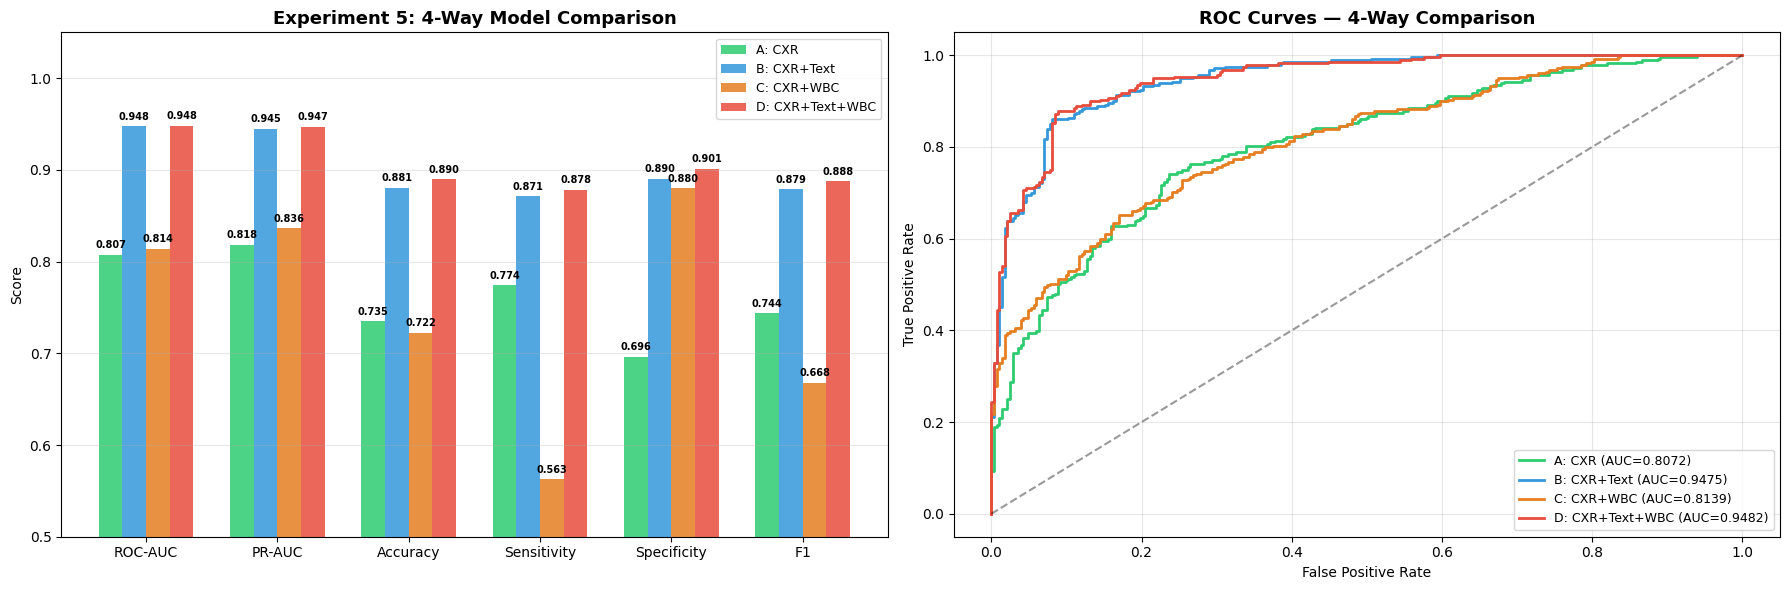

Saved: C:\2026\PneumoFusionNet\mimic\main\outputs\Experiment_5_4way_comparison\exp5_4way_comparison.png


In [16]:
# --- CELL 15: 4-Way Comparison Visualizations ---
fig, axes = plt.subplots(1, 2, figsize=(18, 6))

metrics = ['roc_auc', 'pr_auc', 'accuracy', 'sensitivity', 'specificity', 'f1']
labels_m = ['ROC-AUC', 'PR-AUC', 'Accuracy', 'Sensitivity', 'Specificity', 'F1']
colors = ['#2ecc71', '#3498db', '#e67e22', '#e74c3c']
model_labels = ['A: CXR', 'B: CXR+Text', 'C: CXR+WBC', 'D: CXR+Text+WBC']

x = np.arange(len(metrics))
width = 0.18
for i, (r, c, ml) in enumerate(zip(all_results, colors, model_labels)):
    vals = [r[m] for m in metrics]
    bars = axes[0].bar(x + i*width - 1.5*width, vals, width, label=ml, color=c, alpha=0.85)
    for bar, val in zip(bars, vals):
        axes[0].text(bar.get_x() + bar.get_width()/2., bar.get_height() + 0.005,
                     f'{val:.3f}', ha='center', va='bottom', fontsize=7, fontweight='bold')

axes[0].set_xticks(x); axes[0].set_xticklabels(labels_m, fontsize=10)
axes[0].set_ylim(0.5, 1.05); axes[0].set_ylabel('Score')
axes[0].set_title('Experiment 5: 4-Way Model Comparison', fontsize=13, fontweight='bold')
axes[0].legend(fontsize=9); axes[0].grid(axis='y', alpha=0.3)

for probs, lbls, c, ml in [(test_probs_a, test_labels_a, colors[0], model_labels[0]),
                           (test_probs_b, test_labels_b, colors[1], model_labels[1]),
                           (test_probs_c, test_labels_c, colors[2], model_labels[2]),
                           (test_probs_d, test_labels_d, colors[3], model_labels[3])]:
    fpr, tpr, _ = roc_curve(lbls, probs)
    auc = roc_auc_score(lbls, probs)
    axes[1].plot(fpr, tpr, lw=2, color=c, label=f'{ml} (AUC={auc:.4f})')

axes[1].plot([0,1], [0,1], 'k--', alpha=0.4)
axes[1].set_xlabel('False Positive Rate'); axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curves — 4-Way Comparison', fontsize=13, fontweight='bold')
axes[1].legend(loc='lower right', fontsize=9); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'exp5_4way_comparison.png'), dpi=200, bbox_inches='tight')
plt.show()
print(f'Saved: {os.path.join(SAVE_DIR, "exp5_4way_comparison.png")}')


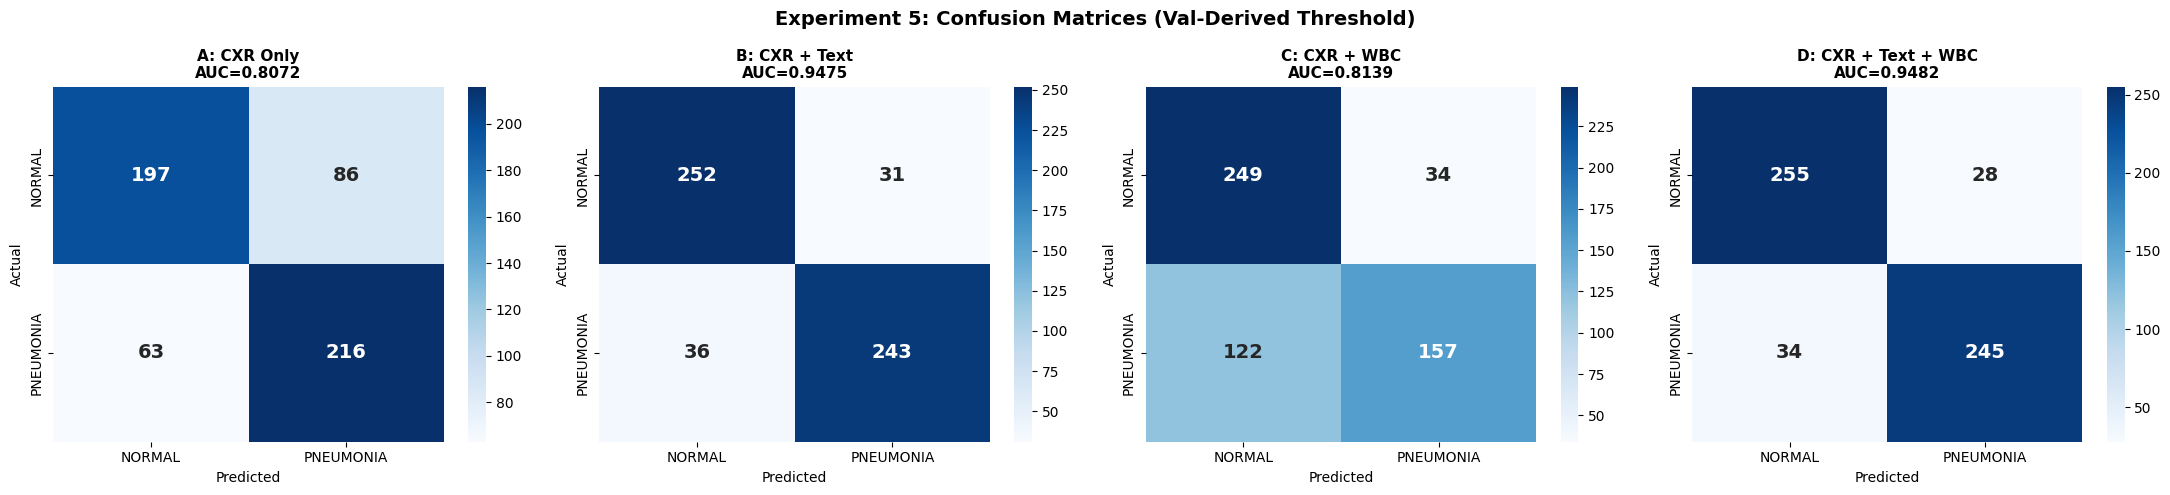

Saved: C:\2026\PneumoFusionNet\mimic\main\outputs\Experiment_5_4way_comparison\exp5_confusion_matrices.png


In [17]:
# --- CELL 16: Confusion Matrices ---
fig, axes = plt.subplots(1, 4, figsize=(22, 5))

for ax, r, probs, lbls, title in zip(axes,
    all_results,
    [test_probs_a, test_probs_b, test_probs_c, test_probs_d],
    [test_labels_a, test_labels_b, test_labels_c, test_labels_d],
    ['A: CXR Only', 'B: CXR + Text', 'C: CXR + WBC', 'D: CXR + Text + WBC']):

    preds = (np.array(probs) >= r['threshold']).astype(int)
    cm = confusion_matrix(np.array(lbls), preds)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=CLASSES, yticklabels=CLASSES,
                annot_kws={'size': 14, 'fontweight': 'bold'})
    ax.set_title(f'{title}\nAUC={r["roc_auc"]:.4f}', fontsize=11, fontweight='bold')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')

plt.suptitle('Experiment 5: Confusion Matrices (Val-Derived Threshold)', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(SAVE_DIR, 'exp5_confusion_matrices.png'), dpi=200, bbox_inches='tight')
plt.show()
print(f'Saved: {os.path.join(SAVE_DIR, "exp5_confusion_matrices.png")}')


In [18]:
# --- CELL 17: Save Results JSON ---
exp5_results = {
    'experiment': 'Experiment 5: 4-Way Model Comparison',
    'description': 'CXR | CXR+Text | CXR+WBC | CXR+Text+WBC',
    'split': {
        'n_train': len(train_df), 'n_val': len(val_df), 'n_test': len(test_df),
        'train_patients': int(train_df['subject_id'].nunique()),
        'val_patients': int(val_df['subject_id'].nunique()),
        'test_patients': int(test_df['subject_id'].nunique()),
    },
    'wbc_summary': {
        'wbc_available_total': int(df_raw['wbc'].notna().sum()),
        'wbc_missing_total': int(df_raw['wbc'].isna().sum()),
        'wbc_available_pct': round(100 * float(df_raw['wbc'].notna().sum()) / len(df_raw), 1),
        'imputation': 'train-set median',
        'note': 'Retrospective +-2-day clinical lab matching (exploratory analysis)',
    },
    'models': {
        'A_cxr_only': results_a,
        'B_cxr_text': results_b,
        'C_cxr_wbc': results_c,
        'D_cxr_text_wbc': results_d,
    }
}

results_path = os.path.join(SAVE_DIR, 'exp5_results.json')
with open(results_path, 'w') as f:
    json.dump(exp5_results, f, indent=2)
print(f'Saved: {results_path}')
print('\nDone! All 4 models evaluated on the same 562-radiograph test set.')


Saved: C:\2026\PneumoFusionNet\mimic\main\outputs\Experiment_5_4way_comparison\exp5_results.json

Done! All 4 models evaluated on the same 562-radiograph test set.
